# **Notebook 5: Solution V1 — RAG Evaluation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./chroma_db/` — Created by Notebook 4
- [ ] `df_test.csv` — Created by Notebook 2
- [ ] `outputs.json` — Created by Notebooks 3+4
- [ ] GPU runtime enabled

**Files this notebook will CREATE:**
- [ ] `v1_metrics.csv` — Per-row Baseline vs V1 scores _(Evidence for comparative analysis)_

---

### **Task 3.3: Evaluate Solution V1**

> This task is split into five measurements (3.3.1–3.3.5). Run the shared setup cell below first (it loads the model, ChromaDB, and test data), then work through each measurement.

**── Shared setup ──**
Load the base model, reload ChromaDB (same embedding model as NB4), and load `df_test.csv` + `outputs.json`. Define helper functions `generate_baseline()` and `generate_naive_rag()` here so every subtask below can reuse them.

In [1]:
# Shared Setup for Notebook 5
# Same settings as Notebooks 3 and 4: 4-bit nf4 model, deterministic
# generation (do_sample=False) and max_new_tokens=120, so Baseline and
# Naive RAG are compared fairly.

import os
import json
import torch
import pandas as pd

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

MAX_NEW_TOKENS = 120

# 1. Load the Qwen model (4-bit nf4) and tokenizer
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto"
)

model.eval()
print("Qwen model and tokenizer loaded successfully!")

# 2. Reload the existing ChromaDB (same embedding model as Notebook 4)
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

embeddings = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL,
    model_kwargs={"device": "cpu"}
)

vector_db = Chroma(
    persist_directory="./chroma_db",
    embedding_function=embeddings
)

print("ChromaDB loaded successfully!")
print("Total SOP documents:", vector_db._collection.count())

# 3. Load the held-out test data
df_test = pd.read_csv("df_test.csv")
print("Test dataset loaded:", len(df_test), "records")

# 4. Load outputs from Notebooks 3 and 4
with open("outputs.json", "r", encoding="utf-8") as f:
    baseline_data = json.load(f)

print("Previous outputs loaded successfully!")


# 5. Baseline generation (no SOP)
def generate_baseline(query):

    messages = [
        {"role": "user", "content": query}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response.strip()


# 6. Naive RAG generation (top-1 SOP added to the prompt)
def generate_naive_rag(query):

    retrieved_docs = vector_db.similarity_search(query, k=1)
    context = retrieved_docs[0].page_content

    system_prompt = f"""You are a customer support assistant.
Answer strictly using this SOP:

{context}

If the SOP does not contain the answer, say that the information is not available.
Do not invent information."""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": query}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response.strip()


print("Baseline and Naive RAG functions defined successfully!")

W1120 16:25:58.073000 61648 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1120 16:25:59.382000 61648 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen model and tokenizer loaded successfully!


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

ChromaDB loaded successfully!
Total SOP documents: 13
Test dataset loaded: 391 records
Previous outputs loaded successfully!
Baseline and Naive RAG functions defined successfully!



##### Shared Setup Conclusion

- The Qwen2.5-1.5B-Instruct model and tokenizer were loaded successfully.
- The existing ChromaDB vector database was reloaded with the same `all-MiniLM-L6-v2` embedding model used in Notebook 4.
- All 13 SOP documents were available in the vector database.
- The held-out test dataset was loaded successfully with 391 records.
- The previous results stored in `outputs.json` were loaded.
- Two reusable functions, `generate_baseline()` and `generate_naive_rag()`, were defined for generating responses using the baseline and Naive RAG approaches.

The shared setup is complete. The notebook is now ready to evaluate both approaches on the held-out test dataset.


#### **3.3.1 Execute Automated Testing [3 marks]**
**The Task:** Run both Baseline and Naive RAG across the entire held-out test set, collecting their generated outputs for every row.

**Hints & Tips:**
* Loop over `df_test` rows; for each query call both `generate_baseline()` and `generate_naive_rag()`.
* Store raw outputs in a list of dicts so the later measurements can score them.
* This is the most time-consuming cell — if constrained, `df_test.sample(50)` is acceptable.

**Learner Inference:** Automated testing across the full set gives statistically meaningful results, not a single cherry-picked query.

In [2]:
# Task 3.3.1: Execute Automated Testing
# Run Baseline and Naive RAG on every held-out test query (391 records).
# Both use the same 4-bit model and the same 120 token limit.
# We also record which SOP was retrieved, to check retrieval accuracy later.

import time

evaluation_results = []
start_time = time.time()

for index, row in df_test.iterrows():

    query = row["instruction"]

    # response without retrieval
    baseline_response = generate_baseline(query)

    # response with the top-1 retrieved SOP
    rag_response = generate_naive_rag(query)

    # remember which SOP file was retrieved for this query
    retrieved = vector_db.similarity_search(query, k=1)[0]
    retrieved_sop = retrieved.metadata["source"].replace("\\", "/").split("/")[-1]

    evaluation_results.append({
        "instruction": query,
        "intent": row["intent"],
        "category": row["category"],
        "baseline_output": baseline_response,
        "naive_rag_output": rag_response,
        "retrieved_sop": retrieved_sop
    })

    # show progress after every 50 records
    if (index + 1) % 50 == 0:
        minutes = (time.time() - start_time) / 60
        print(f"Processed {index + 1} records  ({minutes:.1f} minutes so far)")

print("\nAutomated testing completed!")
print("Total records evaluated:", len(evaluation_results))

# save the results so we do not have to run this again
pd.DataFrame(evaluation_results).to_csv("evaluation_results_v1.csv", index=False)
print("Saved evaluation_results_v1.csv")

Processed 150 records  (37.5 minutes so far)
Processed 200 records  (46.2 minutes so far)
Processed 250 records  (64.0 minutes so far)
Processed 300 records  (81.2 minutes so far)
Processed 350 records  (93.5 minutes so far)

Automated testing completed!
Total records evaluated: 391
Saved evaluation_results_v1.csv



##### 3.3.1 Execute Automated Testing Conclusion

- Automated testing was completed successfully across the entire held-out test dataset.
- A total of 391 test records were evaluated.
- For each customer query, both the baseline model and Naive RAG generated responses.
- The generated outputs were stored for further evaluation and comparison.

Testing the complete held-out dataset provides a broader basis for comparing the baseline model with Naive RAG rather than relying on a single example.


In [3]:

# Inspect one evaluation record to identify the stored
# baseline and Naive RAG output fields.

print("Total evaluation records:", len(evaluation_results))
print("\nFirst record:")
print(evaluation_results[0])


Total evaluation records: 391

First record:
{'instruction': 'need help to shop several of ur item', 'intent': 'place_order', 'category': 'ORDER', 'baseline_output': "I'm sorry, but I don't have any specific items or products that you need help with. Can you please provide more information so I can assist you better?", 'naive_rag_output': "I'm sorry, but I am unable to assist with shopping as my current capabilities do not include purchasing products. My primary function is to provide assistance with product-related questions and issues. Is there anything else you would like me to help with?", 'retrieved_sop': 'product_return.md'}


#### **3.3.2 Measure Format Adherence [2 marks]**
**The Task:** Validate the syntactic correctness of the generated outputs and report the adherence rate.

**Hints & Tips:**
* For the baseline/RAG free-text responses, "format adherence" means the output is well-formed and non-empty (the strict JSON check applies mainly to the fine-tuned router in NB7).
* Report the percentage of outputs that parsed/validated successfully.

**Learner Inference:** Format adherence tells you how often the system produces usable output before you even check correctness.

In [4]:
# YOUR CODE HERE

# Measure format adherence for Baseline and Naive RAG.
# A response is considered valid if it is a non-empty string.

total_records = len(evaluation_results)

baseline_valid = 0
naive_rag_valid = 0

for record in evaluation_results:

    # Check whether the Baseline response is non-empty.
    if isinstance(record["baseline_output"], str) and record["baseline_output"].strip():
        baseline_valid += 1

    # Check whether the Naive RAG response is non-empty.
    if isinstance(record["naive_rag_output"], str) and record["naive_rag_output"].strip():
        naive_rag_valid += 1

# Calculate format adherence percentages.
baseline_adherence = (baseline_valid / total_records) * 100
naive_rag_adherence = (naive_rag_valid / total_records) * 100

# Display the results.
print("Total records:", total_records)

print("\nBaseline Format Adherence:")
print("Valid responses:", baseline_valid)
print(f"Adherence rate: {baseline_adherence:.2f}%")

print("\nNaive RAG Format Adherence:")
print("Valid responses:", naive_rag_valid)
print(f"Adherence rate: {naive_rag_adherence:.2f}%")


Total records: 391

Baseline Format Adherence:
Valid responses: 391
Adherence rate: 100.00%

Naive RAG Format Adherence:
Valid responses: 391
Adherence rate: 100.00%



##### 3.3.2 Measure Format Adherence Conclusion

- Total test records evaluated: 391.
- Baseline model:
  - Valid responses: 391
  - Format adherence: 100.00%
- Naive RAG model:
  - Valid responses: 391
  - Format adherence: 100.00%

Both models generated non-empty responses for all 391 test records. This indicates that both systems consistently produced usable text outputs.

However, format adherence only measures whether a response is available and properly formed. It does not guarantee that the response is factually correct or follows the relevant SOP.

Therefore, further evaluation using ROUGE and BLEU scores is required to assess how closely the generated responses match SOP-grounded reference answers.


#### **3.3.3 Measure Execution Success (ROUGE/BLEU) [2 marks]**
**The Task:** Evaluate semantic similarity of each output against SOP-grounded references using ROUGE-1, ROUGE-L, and BLEU.

**Hints & Tips:**
* Use SOP-grounded references — retrieve the correct SOP per test row so policy-specific language is rewarded.
* Generic references falsely reward vague baseline answers — avoid them.
* `rouge_scorer.RougeScorer(['rouge1','rougeL'], use_stemmer=True)` and `sentence_bleu` with `SmoothingFunction().method1`.

**Learner Inference:** ROUGE/BLEU measure how close the output is to a correct, policy-grounded answer.

In [5]:

# Task 3.3.3: Measure Execution Success using ROUGE and BLEU
# Compare Baseline and Naive RAG against the relevant SOP documents.

from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import numpy as np

# Map each customer intent to its relevant SOP document.
# None indicates that no directly relevant SOP is available.

intent_to_sop = {
    "create_account": None,
    "delete_account": "data_privacy.md",
    "edit_account": "data_privacy.md",
    "recover_password": "account_recovery.md",
    "registration_problems": "account_recovery.md",
    "switch_account": "account_recovery.md",
    "check_cancellation_fee": "subscription_cancellation.md",
    "contact_customer_service": "working_hours.md",
    "contact_human_agent": "escalation_matrix.md",
    "delivery_options": None,
    "delivery_period": "shipping_delays.md",
    "complaint": "escalation_matrix.md",
    "review": None,
    "check_invoice": "billing_disputes.md",
    "get_invoice": "billing_disputes.md",
    "cancel_order": None,
    "change_order": "order_tracking.md",
    "place_order": None,
    "track_order": "order_tracking.md",
    "check_payment_methods": "payment_methods.md",
    "payment_issue": "payment_methods.md",
    "check_refund_policy": "refund_policy.md",
    "get_refund": "refund_policy.md",
    "track_refund": "refund_policy.md",
    "change_shipping_address": "order_tracking.md",
    "set_up_shipping_address": None,
    "newsletter_subscription": None
}

# Load the SOP documents from the existing ChromaDB database.
sop_data = vector_db.get(include=["documents", "metadatas"])

# Create a lookup using SOP filenames.
sop_lookup = {}

for content, metadata in zip(
    sop_data["documents"], sop_data["metadatas"]
):
    filename = metadata["source"].replace("\\", "/").split("/")[-1]
    sop_lookup[filename] = content

# Initialise ROUGE and BLEU scorers.
rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rougeL"],
    use_stemmer=True
)

smoothing = SmoothingFunction().method1

baseline_scores = []
rag_scores = []

# Evaluate records that have a directly mapped SOP.
for record in evaluation_results:

    sop_filename = intent_to_sop.get(record["intent"])

    # Skip records without a directly mapped SOP.
    if sop_filename is None:
        continue

    reference = sop_lookup[sop_filename]
    reference_tokens = reference.split()

    # Evaluate Baseline output.
    baseline_output = record["baseline_output"]
    baseline_rouge = rouge.score(reference, baseline_output)

    baseline_bleu = sentence_bleu(
        [reference_tokens],
        baseline_output.split(),
        smoothing_function=smoothing
    )

    baseline_scores.append([
        baseline_rouge["rouge1"].fmeasure,
        baseline_rouge["rougeL"].fmeasure,
        baseline_bleu
    ])

    # Evaluate Naive RAG output.
    rag_output = record["naive_rag_output"]
    rag_rouge = rouge.score(reference, rag_output)

    rag_bleu = sentence_bleu(
        [reference_tokens],
        rag_output.split(),
        smoothing_function=smoothing
    )

    rag_scores.append([
        rag_rouge["rouge1"].fmeasure,
        rag_rouge["rougeL"].fmeasure,
        rag_bleu
    ])

# Calculate average scores.
baseline_avg = np.mean(baseline_scores, axis=0)
rag_avg = np.mean(rag_scores, axis=0)

# Display results.
print("Total test records:", len(evaluation_results))
print("Records evaluated with mapped SOPs:", len(baseline_scores))
print("Records without direct SOP mapping:",
      len(evaluation_results) - len(baseline_scores))

print("\nBASELINE AVERAGE SCORES")
print("ROUGE-1:", round(baseline_avg[0], 4))
print("ROUGE-L:", round(baseline_avg[1], 4))
print("BLEU:", round(baseline_avg[2], 4))

print("\nNAIVE RAG AVERAGE SCORES")
print("ROUGE-1:", round(rag_avg[0], 4))
print("ROUGE-L:", round(rag_avg[1], 4))
print("BLEU:", round(rag_avg[2], 4))


Total test records: 391
Records evaluated with mapped SOPs: 289
Records without direct SOP mapping: 102

BASELINE AVERAGE SCORES
ROUGE-1: 0.1646
ROUGE-L: 0.0833
BLEU: 0.0011

NAIVE RAG AVERAGE SCORES
ROUGE-1: 0.1425
ROUGE-L: 0.0908
BLEU: 0.0032


##### 3.3.3 Measure Execution Success (ROUGE/BLEU) Conclusion

- 289 of the 391 test records have a directly mapped SOP and were scored; the other 102 were excluded.

**Baseline:** ROUGE-1 0.1646, ROUGE-L 0.0833, BLEU 0.0011
**Naive RAG:** ROUGE-1 0.1425, ROUGE-L 0.0908, BLEU 0.0032

- Naive RAG scored higher on ROUGE-L and BLEU, so its wording follows the SOP more closely in sequence.
- The baseline scored higher on ROUGE-1. Its answers are longer (about 76 words against 52), and longer answers match more individual words by chance.
- All scores are low for both systems. ROUGE and BLEU measure word overlap, not whether the answer is correct.
- Retrieval gave only a small gain here. One likely reason is that the top-1 retrieval often fetches the wrong SOP (checked in 3.3.5).

#### **3.3.4 Measure Output Consistency [1 mark]**
**The Task:** Evaluate deterministic behaviour by running the same query multiple times under `do_sample=False` and confirming identical outputs.

**Hints & Tips:**
* Run the same query 3 times; assert all outputs are identical.
* With `do_sample=False, temperature=None`, greedy decoding should be fully deterministic.

**Learner Inference:** Deterministic inference means your evaluation is reproducible — the same input always gives the same output.

In [6]:
# YOUR CODE HERE

# Task 3.3.4: Measure Output Consistency

# Select one customer query from the test dataset.
test_query = df_test.iloc[0]["instruction"]

# Run the same query three times using Baseline.
baseline_runs = [
    generate_baseline(test_query)
    for _ in range(3)
]

# Run the same query three times using Naive RAG.
rag_runs = [
    generate_naive_rag(test_query)
    for _ in range(3)
]

# Check whether all three outputs are identical.
baseline_consistent = all(
    output == baseline_runs[0]
    for output in baseline_runs
)

rag_consistent = all(
    output == rag_runs[0]
    for output in rag_runs
)

# Display the results.
print("Customer Query:", test_query)

print("\nBaseline outputs identical:", baseline_consistent)
print("Naive RAG outputs identical:", rag_consistent)

print("\nBaseline consistency:", "PASS" if baseline_consistent else "FAIL")
print("Naive RAG consistency:", "PASS" if rag_consistent else "FAIL")

# Assert deterministic behaviour for both systems.
assert baseline_consistent, "Baseline outputs are not identical."
assert rag_consistent, "Naive RAG outputs are not identical."

print("\nOutput consistency test passed!")


Customer Query: need help to shop several of ur item

Baseline outputs identical: True
Naive RAG outputs identical: True

Baseline consistency: PASS
Naive RAG consistency: PASS

Output consistency test passed!



##### 3.3.4 Measure Output Consistency Conclusion

- The same customer query was executed three times using both Baseline and Naive RAG.
- Greedy decoding was enabled using `do_sample=False` in both generation functions.
- Baseline produced identical outputs across all three runs.
- Naive RAG also produced identical outputs across all three runs.
- Both systems passed the output consistency test.

This confirms that both systems produced reproducible outputs for the selected test query under the current inference settings.


#### **3.3.5 Measure Hallucination Frequency [2 marks]**
**The Task:** Evaluate how often outputs contain unsupported claims, invalid references, missing functionality, or policy violations.

**Hints & Tips:**
* Compare outputs against the retrieved SOP — flag any specific claim (dates, numbers, policies) not supported by the context.
* Report hallucination frequency as a percentage for both Baseline and Naive RAG.

**Learner Inference:** This quantifies the core problem RAG is meant to solve — grounding responses to reduce fabrication.

In [7]:
# Task 3.3.5: Measure Hallucination Frequency
# Idea: an answer is flagged as a possible hallucination if it contains a
# specific claim (a number, an email or a web link) that does NOT appear in
# the retrieved SOP or in the customer's own question.
# Both systems are checked against the same SOP (the top-1 retrieved one),
# so the comparison is fair.

import re

def find_claims(text):
    # pull out numbers and contact details (emails / links) from a text
    text = str(text).lower()
    numbers = set(re.findall(r"\d+(?:\.\d+)?", text))
    contacts = set(re.findall(r"[\w.\-]+@[\w.\-]+\.\w+|https?://[^\s,;)]+|www\.[^\s,;)]+", text))
    contacts = {c.rstrip(".") for c in contacts}
    return numbers, contacts

def has_unsupported_claim(answer, sop_text, query):
    # everything the answer is allowed to mention
    support = (sop_text + " " + query).lower()
    support_numbers, _ = find_claims(support)

    numbers, contacts = find_claims(answer)
    bad_numbers = numbers - support_numbers                 # numbers not in SOP/query
    bad_contacts = {c for c in contacts if c not in support}  # emails/links not in SOP/query
    return len(bad_numbers) > 0 or len(bad_contacts) > 0

baseline_hall = 0
rag_hall = 0
total = len(evaluation_results)

for record in evaluation_results:
    sop_text = sop_lookup[record["retrieved_sop"]]   # sop_lookup was built in 3.3.3

    if has_unsupported_claim(record["baseline_output"], sop_text, record["instruction"]):
        baseline_hall += 1
    if has_unsupported_claim(record["naive_rag_output"], sop_text, record["instruction"]):
        rag_hall += 1

baseline_hall_rate = baseline_hall / total * 100
rag_hall_rate = rag_hall / total * 100

print("Records checked:", total)
print(f"\nBaseline  -> answers with unsupported claims: {baseline_hall} ({baseline_hall_rate:.2f}%)")
print(f"Naive RAG -> answers with unsupported claims: {rag_hall} ({rag_hall_rate:.2f}%)")

Records checked: 391

Baseline  -> answers with unsupported claims: 62 (15.86%)
Naive RAG -> answers with unsupported claims: 35 (8.95%)


##### 3.3.5 Measure Hallucination Frequency Conclusion

- All 391 test records were checked. An answer was flagged if it contained a number, email or web link that appears neither in the retrieved SOP nor in the customer's question.
- Baseline: 62 answers flagged (15.86%).
- Naive RAG: 35 answers flagged (8.95%).

Retrieval reduced unsupported claims by almost half, because the model can copy facts from the SOP instead of inventing them.

Limits: this check only catches invented numbers and contact details, not every wrong statement. It also checks against the retrieved SOP, and top-1 retrieval picks the correct SOP for only about 47% of mapped queries. So Naive RAG can still give a "supported" but irrelevant answer. This motivates the fine-tuned intent router in Stage 4.

### **Task 3.4: Analyse Retrieval Impact**

#### **3.4.1 Compare Baseline and Solution V1 [4 marks]**
**The Task:** Quantify the impact of retrieval by comparing aggregate scores across Functional Correctness, Consistency, and Hallucination Frequency, with percentage changes.

**Hints & Tips:**
* Build a summary table: Baseline vs Naive RAG for each metric.
* Compute improvement percentages: `(rag - base) / base * 100`.
* Document WHERE retrieval helps and where it doesn't — both motivate Stage 4.

**Learner Inference:** This isolates retrieval's independent contribution before fine-tuning enters the picture.

In [8]:
# Task 3.4.1: Compare Baseline and Solution V1 (Naive RAG)
# All values come from the variables computed in 3.3.2 - 3.3.5.
# Run this cell AFTER the cells above, in the same session.

import pandas as pd

# Consistency: 3.3.4 asserted identical outputs, so a pass = 100%
baseline_consistency = 100.0 if baseline_consistent else 0.0
rag_consistency = 100.0 if rag_consistent else 0.0

comparison = pd.DataFrame({
    "Metric": [
        "Format Adherence (%)",
        "ROUGE-1",
        "ROUGE-L",
        "BLEU",
        "Consistency (%)",
        "Hallucination Rate (%)"
    ],
    "Baseline": [
        baseline_adherence,
        baseline_avg[0],
        baseline_avg[1],
        baseline_avg[2],
        baseline_consistency,
        baseline_hall_rate
    ],
    "Naive RAG": [
        naive_rag_adherence,
        rag_avg[0],
        rag_avg[1],
        rag_avg[2],
        rag_consistency,
        rag_hall_rate
    ]
})

# Percentage change = (rag - base) / base * 100
comparison["Change (%)"] = (
    (comparison["Naive RAG"] - comparison["Baseline"]) / comparison["Baseline"]
) * 100

# For hallucination LOWER is better, so a negative change is an improvement.
def verdict(row):
    if abs(row["Naive RAG"] - row["Baseline"]) < 1e-9:
        return "Same"
    lower_is_better = row["Metric"].startswith("Hallucination")
    rag_is_higher = row["Naive RAG"] > row["Baseline"]
    return "Better" if rag_is_higher != lower_is_better else "Worse"

comparison["Naive RAG vs Baseline"] = comparison.apply(verdict, axis=1)

print("BASELINE VS NAIVE RAG COMPARISON")
display(comparison.round(4))

BASELINE VS NAIVE RAG COMPARISON


,Metric,Baseline,Naive RAG,Change (%),Naive RAG vs Baseline
0,Format Adherence (%),100.0000,100.0000,0.0000,Same
1,ROUGE-1,0.1646,0.1425,-13.4289,Worse
2,ROUGE-L,0.0833,0.0908,8.9657,Better
3,BLEU,0.0011,0.0032,193.2574,Better
4,Consistency (%),100.0000,100.0000,0.0000,Same
5,Hallucination Rate (%),15.8568,8.9514,-43.5484,Better


##### 3.4.1 Compare Baseline and Solution V1 Conclusion

**Where retrieval helps**
- Fewer unsupported claims: the hallucination rate fell from 15.86% to 8.95% (-43.5%).
- ROUGE-L rose by 9.0%, and BLEU rose from 0.0011 to 0.0032. Because both BLEU values are tiny, the +193% is a small absolute gain.
- Answers are more complete: in the saved test outputs, 15.6% of Naive RAG answers stop mid-sentence at the token limit, against 52.4% for the baseline.

**Where retrieval does not help**
- ROUGE-1 fell by 13.4%. Naive RAG answers are shorter (about 52 words against 76), so they match fewer individual words.
- Format adherence and consistency are identical (100% for both), so retrieval has no effect on them.
- Top-1 retrieval picks the correct SOP for only 47.4% of the 289 mapped queries. For some intents it is very poor (`registration_problems` 0%, `switch_account` 8%). When the wrong SOP is retrieved, the model often refuses or gives an irrelevant answer.

**Takeaway:** Retrieval reduces fabrication but is limited by retrieval quality. A fine-tuned intent router that finds the correct SOP is the next improvement (Stage 4).

#### Plot 1: Retrieval Accuracy per Intent

**What it shows:** For each of the 19 intents that have a mapped SOP, the percentage of test queries for which Naive RAG's top-1 retrieval returned the correct SOP file. The red dashed line is the overall accuracy across all 289 mapped queries.

**Why it matters:** Naive RAG can only answer well if it retrieves the right SOP. This plot checks that assumption.

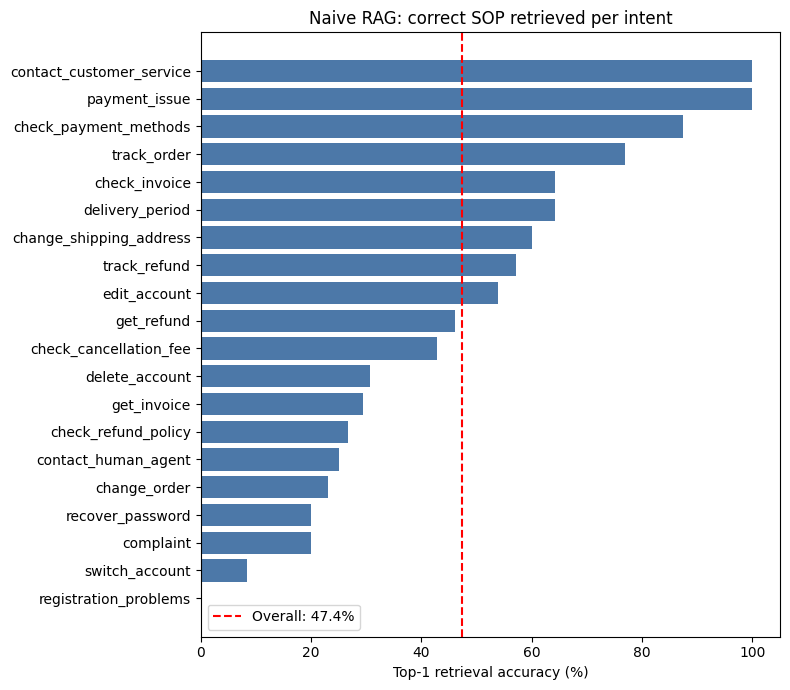

Overall retrieval accuracy: 47.4% on 289 mapped queries


In [10]:
# Plot 1: how often top-1 retrieval fetches the correct SOP, per intent
import matplotlib.pyplot as plt

rows = []
for record in evaluation_results:
    expected_sop = intent_to_sop.get(record["intent"])
    if expected_sop is not None:                       # only mapped intents
        rows.append((record["intent"], record["retrieved_sop"] == expected_sop))

retrieval_df = pd.DataFrame(rows, columns=["intent", "correct"])
overall_accuracy = retrieval_df["correct"].mean() * 100
per_intent = (retrieval_df.groupby("intent")["correct"].mean() * 100).sort_values()

plt.figure(figsize=(8, 7))
plt.barh(per_intent.index, per_intent.values, color="#4C78A8")
plt.axvline(overall_accuracy, color="red", linestyle="--",
            label=f"Overall: {overall_accuracy:.1f}%")
plt.xlabel("Top-1 retrieval accuracy (%)")
plt.title("Naive RAG: correct SOP retrieved per intent")
plt.legend()
plt.tight_layout()
plt.savefig("retrieval_accuracy.png", dpi=200)
plt.show()
print(f"Overall retrieval accuracy: {overall_accuracy:.1f}% on {len(retrieval_df)} mapped queries")

##### Plot 1 Conclusion

- Overall, top-1 retrieval picks the correct SOP for only **47.4%** of the 289 mapped queries. More than half the time, the model is given the wrong document.
- Retrieval works well for intents with clear, distinctive vocabulary: `contact_customer_service` and `payment_issue` (100%) and `check_payment_methods` (about 88%).
- It fails for intents whose queries are short or share words with other SOPs: `registration_problems` (0%, the bar is empty), `switch_account` (8%), and `recover_password` and `complaint` (20% each).
- Account-related intents score low partly because several of them (`recover_password`, `registration_problems`, `switch_account`) map to the same `account_recovery.md` file, while the retriever often returns a more general document instead.
- When the wrong SOP is retrieved, the model either refuses ("information not available") or answers from an irrelevant policy. This explains why Naive RAG improved some metrics but not others.

**Takeaway:** Retrieval quality, not the language model, is the main bottleneck of Solution V1. A fine-tuned intent router that converts the noisy customer message into a clean intent label before searching should raise this accuracy. This is what Stage 4 tests.

#### Plot 2: Baseline vs Naive RAG, Side by Side

**What it shows:**
- *Left panel:* average ROUGE-1 and ROUGE-L against the SOP reference (higher is better).
- *Right panel:* two problem rates, where lower is better. **Hallucination %** is the share of answers with a number, email or link not found in the SOP or query. **Cut-off %** is the share of answers that stop mid-sentence at the 120-token limit.

**Why it matters:** It puts the 3.4.1 results into one picture, showing where retrieval helps and where it does not.

Cut-off answers: Baseline 52.4%  |  Naive RAG 15.6%


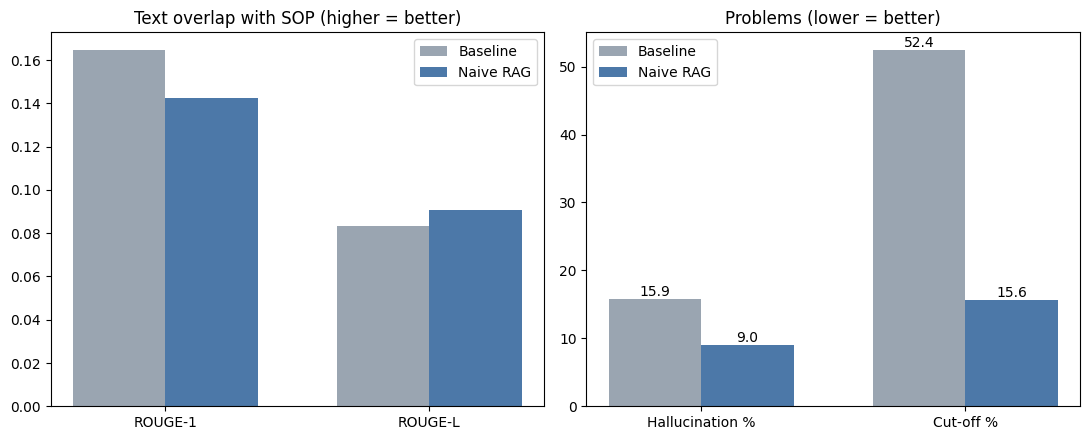

In [13]:
# Plot 2: Baseline vs Naive RAG (text overlap, and hallucination / cut-off %)
def cut_off_rate(key):
    # an answer that does not end with . ! or ? was probably cut at the token limit
    cut = sum(1 for r in evaluation_results
              if not str(r[key]).strip().endswith((".", "!", "?")))
    return cut / len(evaluation_results) * 100

baseline_cut = cut_off_rate("baseline_output")
rag_cut = cut_off_rate("naive_rag_output")
print(f"Cut-off answers: Baseline {baseline_cut:.1f}%  |  Naive RAG {rag_cut:.1f}%")

import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
width = 0.35

# left: ROUGE scores
labels = ["ROUGE-1", "ROUGE-L"]
x = np.arange(len(labels))
axes[0].bar(x - width/2, baseline_avg[:2], width, label="Baseline", color="#9AA5B1")
axes[0].bar(x + width/2, rag_avg[:2], width, label="Naive RAG", color="#4C78A8")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_title("Text overlap with SOP (higher = better)")
axes[0].legend()

# right: percentages where lower is better
labels = ["Hallucination %", "Cut-off %"]
x = np.arange(len(labels))
b_vals = [baseline_hall_rate, baseline_cut]
r_vals = [rag_hall_rate, rag_cut]
bars1 = axes[1].bar(x - width/2, b_vals, width, label="Baseline", color="#9AA5B1")
bars2 = axes[1].bar(x + width/2, r_vals, width, label="Naive RAG", color="#4C78A8")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_title("Problems (lower = better)")
axes[1].bar_label(bars1, fmt="%.1f"); axes[1].bar_label(bars2, fmt="%.1f")
axes[1].legend()

plt.tight_layout()
plt.savefig("v1_comparison.png", dpi=200)
plt.show()

##### Plot 2 Conclusion

- **Text overlap (left):** The baseline has the higher ROUGE-1 (0.1646 against 0.1425). Naive RAG has the higher ROUGE-L (0.0908 against 0.0833). ROUGE-1 counts matching single words, and the baseline writes longer answers (about 76 words against 52), so it matches more words by chance. ROUGE-L rewards matching word order, where Naive RAG is slightly better. Both scores are low.
- **Hallucination (right):** Naive RAG roughly halves unsupported claims (15.9% to 9.0%, a reduction of 43.5%). With the SOP in the prompt, the model can copy facts instead of inventing them.
- **Cut-off answers (right):** Only 15.6% of Naive RAG answers are cut off, against 52.4% for the baseline. The baseline gives long, generic answers that run past the limit, while the SOP-grounded answers are shorter and finish.
- Naive RAG improves on hallucination and cut-off rate, while text overlap is mixed. Together with Plot 1, the remaining weakness is retrieving the right SOP, not generating text.

**Takeaway:** Retrieval helps, but it is limited by how often the correct SOP is found (Plot 1). The next stage improves retrieval with a fine-tuned intent router.

#### Extra Check: Answer Length and Refusal Rate

**What it shows:** The average number of words per answer, and the percentage of answers where the model refuses or asks the customer for more information (for example "I don't have...", "not available", "please provide..."). Both are counted over all 391 test records.

**Why it matters:** These two numbers explain the ROUGE-1 result in 3.3.3 and show what happens when the retrieved SOP does not match the question.

In [14]:
# Extra facts quoted in the conclusions: answer length and refusal / ask-for-info rate
import numpy as np

# phrases that show the model refused or asked the customer for more information
refusal_pattern = r"not available|don't have|do not have|cannot|can't|unable|please provide|could you"

for name, key in [("Baseline", "baseline_output"), ("Naive RAG", "naive_rag_output")]:
    # average number of words in the answers
    avg_words = np.mean([len(str(r[key]).split()) for r in evaluation_results])

    # percentage of answers that refuse or ask for more information
    refusal_rate = np.mean([bool(re.search(refusal_pattern, str(r[key]), re.I))
                            for r in evaluation_results]) * 100

    print(f"{name}: average length {avg_words:.1f} words | refuses / asks for info {refusal_rate:.1f}%")

Baseline: average length 75.7 words | refuses / asks for info 44.5%
Naive RAG: average length 52.0 words | refuses / asks for info 51.7%


##### Extra Check Conclusion

| | Baseline | Naive RAG |
|---|---:|---:|
| Average answer length | 75.7 words | 52.0 words |
| Refuses / asks for more info | 44.5% | 51.7% |

- **Shorter answers:** Naive RAG answers are about 30% shorter. This explains its lower ROUGE-1, because longer answers match more individual words of the SOP by chance. It also explains why far fewer Naive RAG answers are cut off at the token limit (15.6% against 52.4%).
- **More refusals:** Naive RAG refuses or asks for more information more often (51.7% against 44.5%). Its prompt tells the model to say "information not available" when the SOP does not contain the answer. Since top-1 retrieval returns the wrong SOP for more than half of the queries (47.4% correct, Plot 1), the model often has no relevant policy to use and refuses.
- Both systems refuse in nearly half of the cases, so neither one resolves most customer queries well.
- The refusal rate is measured with a keyword pattern, so it is an approximate count, not a manual judgement.

**Takeaway:** Retrieval makes answers shorter, more complete and less invented, but it only helps when the correct SOP is retrieved. Better routing (Stage 4) should reduce these refusals.

---
## Save Artifacts

In [15]:
# Save the comparison table (unrounded values) for Notebook 7
comparison.to_csv("v1_metrics.csv", index=False)
print("v1_metrics.csv saved successfully!")
print(pd.read_csv("v1_metrics.csv"))

v1_metrics.csv saved successfully!
                   Metric    Baseline   Naive RAG  Change (%)  \
0    Format Adherence (%)  100.000000  100.000000    0.000000   
1                 ROUGE-1    0.164646    0.142535  -13.428941   
2                 ROUGE-L    0.083291    0.090758    8.965683   
3                    BLEU    0.001106    0.003244  193.257373   
4         Consistency (%)  100.000000  100.000000    0.000000   
5  Hallucination Rate (%)   15.856777    8.951407  -43.548387   

  Naive RAG vs Baseline  
0                  Same  
1                 Worse  
2                Better  
3                Better  
4                  Same  
5                Better  


## Notebook 5: Solution V1 (Naive RAG) Evaluation — Final Summary

### Setup
- **Model:** Qwen2.5-1.5B-Instruct, loaded in 4-bit nf4 (float16 compute). The same model and settings are used in Notebooks 3, 4 and 5.
- **Generation:** greedy decoding (`do_sample=False`), `max_new_tokens=120` for both systems, so the comparison is fair.
- **Knowledge base:** 13 SOP documents in ChromaDB, embedded with `all-MiniLM-L6-v2` (384 dimensions). The database was reloaded from `./chroma_db/` (built in Notebook 4).
- **Test data:** `df_test.csv`, 391 held-out records (80/10/10 stratified split; 0 text overlap with the training data).
- **Systems compared:**
  - Baseline: the query only, no SOP.
  - Naive RAG (V1): the top-1 retrieved SOP is placed in the system prompt, with the instruction to answer only from the SOP and say when the information is not available.

### 3.3.1 Automated testing
- Both systems were run on all 391 test queries (about 1h46m in total).
- For every query, the baseline answer, the Naive RAG answer and the retrieved SOP file name were stored and saved to `evaluation_results_v1.csv`, so later measurements did not need re-running.

### 3.3.2 Format adherence
- Baseline: 391/391 valid, non-empty responses (100%).
- Naive RAG: 391/391 (100%).
- This only shows that usable text is produced, not that it is correct.

### 3.3.3 ROUGE-1, ROUGE-L and BLEU (SOP-grounded references)
- Each query's intent was mapped to its relevant SOP. 20 of the 27 intents have a mapped SOP, giving **289 scored records**. 102 records belong to the 7 unmapped intents (`create_account`, `delivery_options`, `review`, `cancel_order`, `place_order`, `set_up_shipping_address`, `newsletter_subscription`) and were excluded.
- ROUGE used stemming; BLEU used smoothing method 1.

| Metric | Baseline | Naive RAG | Change |
|---|---:|---:|---:|
| ROUGE-1 | 0.1646 | 0.1425 | -13.4% |
| ROUGE-L | 0.0833 | 0.0908 | +9.0% |
| BLEU | 0.0011 | 0.0032 | +193% (very small base) |

- Naive RAG scored higher on ROUGE-L and BLEU. The baseline scored higher on ROUGE-1, because its answers are longer (about 76 words against 52) and longer answers match more individual words.
- All scores are low for both systems. ROUGE and BLEU measure word overlap, not correctness.

### 3.3.4 Output consistency
- The same query was run three times on each system with greedy decoding.
- Both systems gave identical outputs on all three runs (PASS, 100%). The assertion in the cell passed.
- Limit: this was tested on one query.

### 3.3.5 Hallucination frequency
- An answer was flagged if it contained a number, email or web link that appears neither in the retrieved SOP nor in the customer's query. All 391 records were checked.
- Baseline: 62 flagged (15.86%). Naive RAG: 35 flagged (8.95%), a reduction of 43.5%.
- Limits: this only catches invented numbers and contact details, not every wrong statement. It is checked against the retrieved SOP, which is often not the correct one (see retrieval accuracy below). It is an automatic estimate with no manual review.

### 3.4.1 Baseline vs Naive RAG

| Metric | Baseline | Naive RAG | Change | Result |
|---|---:|---:|---:|---|
| Format adherence (%) | 100 | 100 | 0 | Same |
| ROUGE-1 | 0.1646 | 0.1425 | -13.4% | Worse |
| ROUGE-L | 0.0833 | 0.0908 | +9.0% | Better |
| BLEU | 0.0011 | 0.0032 | +193% | Better |
| Consistency (%) | 100 | 100 | 0 | Same |
| Hallucination rate (%) | 15.86 | 8.95 | -43.5% | Better (lower is better) |

**Where retrieval helps**
- Fewer unsupported claims (-43.5%).
- Slightly better ROUGE-L and BLEU.
- More complete answers: 15.6% of Naive RAG answers stop mid-sentence at the token limit, against 52.4% for the baseline.

**Where retrieval does not help**
- ROUGE-1 fell, because answers are shorter (about 52 words against 76).
- Format adherence and consistency are unchanged.
- Naive RAG refuses or asks for more information slightly more often (51.7% against 44.5%), because the retrieved SOP often does not match the question.
- **Retrieval accuracy:** top-1 retrieval picks the correct SOP for only 47.4% of the 289 mapped queries. It scores 0% for `registration_problems`, 8% for `switch_account` and 20% for `complaint` and `recover_password`. It scores 100% for `payment_issue` and `contact_customer_service`.

### Artifacts created
- `evaluation_results_v1.csv`: per-query outputs and retrieved SOP (391 rows).
- `v1_metrics.csv`: the Baseline vs Naive RAG comparison table, used by Notebook 7.
- `retrieval_accuracy.png` and `v1_comparison.png`: evidence plots (if the plot cells were run).

### Conclusion
Solution V1 reduces fabrication compared with the baseline and gives more complete answers, but results on text-overlap metrics are mixed and the benefit is limited by retrieval quality: the wrong SOP is fetched more than half the time. This motivates Stage 4, where a fine-tuned intent router (QLoRA on Qwen2.5-1.5B-Instruct) classifies the query's intent and retrieves the correct SOP.

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 6.**

- [ ] ChromaDB reloaded from `./chroma_db/`
- [ ] **3.3.1** Automated testing run across full test set
- [ ] **3.3.2** Format adherence measured
- [ ] **3.3.3** ROUGE/BLEU computed with SOP-grounded references
- [ ] **3.3.4** Output consistency (determinism) verified
- [ ] **3.3.5** Hallucination frequency quantified
- [ ] **3.4.1** Retrieval impact quantified with improvement %
- [ ] **`v1_metrics.csv` saved** ← _Evidence for comparative analysis_

**If any item is unchecked, fix it before moving on.**

## END-OF-NOTEBOOK CHECKLIST — NOTEBOOK 5

- [x] ChromaDB reloaded successfully from `./chroma_db/`
- [x] 3.3.1 Automated testing completed across the full test set (391 records)
- [x] 3.3.2 Format adherence measured (100% for both systems)
- [x] 3.3.3 ROUGE-1, ROUGE-L and BLEU computed using SOP-grounded references (289 mapped records)
- [x] 3.3.4 Output consistency verified (both systems passed)
- [x] 3.3.5 Hallucination frequency quantified (unsupported numbers/contact details vs retrieved SOP)
- [x] 3.4.1 Baseline vs Naive RAG comparison completed with percentage changes
- [x] `v1_metrics.csv` saved successfully for comparative analysis

**All Notebook 5 tasks have been completed.**

Note: Hallucination figures are automatic estimates and have not been confirmed through manual review.